# https://geonetwork.nci.org.au/geonetwork/srv/eng/catalog.search#/metadata/f2795_8238_4580_6260
# https://github.com/DWER-WA/CSI-DataAnalysis/blob/main/01_accessing_data.ipynb

In [9]:
import xarray as xr
import matplotlib.pyplot as plt

In [26]:
BASE_URL = (
    "https://thredds.nci.org.au/thredds/dodsC/zz63/"
    "NARCliM2-0-derived/output-CMIP6/DD"
)

BASE_URL

'https://thredds.nci.org.au/thredds/dodsC/zz63/NARCliM2-0-derived/output-CMIP6/DD'

In [ ]:
domain = "NARCliM2-0-SEAus-04"
organisation = "NSW-Government"

gcm = ["ACCESS-ESM1-5", "EC-Earth3-Veg", "MPI-ESM1-2-HR", "NorESM2-MM", "UKESM1-0-LL"]
rcm = ["NARCliM2-0-WRF412R3", "NARCliM2-0-WRF412R5"]
experiment = ["historical", "ssp126", "ssp245", "ssp370"]
variant = ["r1i1p1f1", " r1i1p1f2", "r6i1p1f1"]

frequency = "mon"
variable = ["tasmax", "R10mm", "R20mm", "R99p", "SPI03", "SPI06", "SPI12"]
version = "v1-r1"

In [50]:
# only one model at this point 

domain = "NARCliM2-0-SEAus-04"
organisation = "NSW-Government"

gcm = "ACCESS-ESM1-5"
rcm = "NARCliM2-0-WRF412R3"
experiment = "ssp245"
variant = "r6i1p1f1"

frequency = "mon"
variable = "SPI03"
version = "v1-r1"

In [51]:
file_url = (
    f"{BASE_URL}/"
    f"{domain}/{organisation}/"
    f"{gcm}/{experiment}/{variant}/"
    f"{rcm}/{version}/{frequency}/{variable}/latest/"
    f"{variable}_{domain}_{gcm}_{experiment}_{variant}_"
    f"{organisation}_{rcm}_{version}_{frequency}_195101-210012.nc"
)

file_url

'https://thredds.nci.org.au/thredds/dodsC/zz63/NARCliM2-0-derived/output-CMIP6/DD/NARCliM2-0-SEAus-04/NSW-Government/ACCESS-ESM1-5/ssp245/r6i1p1f1/NARCliM2-0-WRF412R3/v1-r1/mon/SPI03/latest/SPI03_NARCliM2-0-SEAus-04_ACCESS-ESM1-5_ssp245_r6i1p1f1_NSW-Government_NARCliM2-0-WRF412R3_v1-r1_mon_195101-210012.nc'

In [52]:
ds = xr.open_dataset(file_url)
ds

<xarray.Dataset> Size: 2GB
Dimensions:    (time: 1800, bnds: 2, rlat: 474, rlon: 594, crs: 1)
Coordinates:
  * time       (time) datetime64[ns] 14kB 1951-01-16T12:00:00 ... 2100-12-16T...
  * rlat       (rlat) float64 4kB -10.53 -10.49 -10.46 -10.42 ... 6.05 6.09 6.12
  * rlon       (rlon) float64 5kB -179.7 -179.7 -179.6 ... 179.6 179.7 179.7
    lat        (rlat, rlon) float64 2MB ...
    lon        (rlat, rlon) float64 2MB ...
  * crs        (crs) uint8 1B 0
Dimensions without coordinates: bnds
Data variables:
    time_bnds  (time, bnds) datetime64[ns] 29kB ...
    SPI03      (time, rlat, rlon) float32 2GB ...
Attributes: (12/46)
    comment:                         DPIE version of WRF4.1.2
    DPIE_WRF_HASH:                   a051fdc73749349fd244ce8e596088a372bdb0c5
    wrf_options:                     sst_update & tmn_update
    frequency:                       mon
    institution:                     NSW Department of Climate Change, Energy...
    contact:                         NARCliM Team (narclim@environment.nsw.go...
    ...                              ...
    driving_experiment:              update of RCP4.5 based on SSP2
    driving_experiment_id:           ssp245
    input_institution_id:            NSW-Government
    input_instituion:                NSW Department of Climate Change, Energy...
    references:                      Include in publications citations to the...
    history:                         Mon Jun  2 16:10:05 2025: ncatted -O -a ...

In [39]:
var = ds[variable]

print("Units:", var.attrs.get("units"))

Units: 1


In [53]:
# Macquarie Marshes bbox
lon_min, lon_max, lat_min, lat_max = 147.45, 147.606, -30.840, -30.551    

lat, lon = ds["lat"], ds["lon"]
mask = (lat >= lat_min) & (lat <= lat_max) & (lon >= lon_min) & (lon <= lon_max)
sub = ds.where(mask.compute(), drop=True)   # drops rows/cols that are all-NaN

In [41]:
sub

<xarray.Dataset> Size: 1MB
Dimensions:    (time: 1800, bnds: 2, rlat: 8, rlon: 4, crs: 1)
Coordinates:
  * time       (time) datetime64[ns] 14kB 1951-01-16T12:00:00 ... 2100-12-16T...
  * rlat       (rlat) float64 64B -1.27 -1.24 -1.2 -1.17 -1.13 -1.1 -1.06 -1.03
  * rlon       (rlon) float64 32B -169.0 -168.9 -168.9 -168.9
    lat        (rlat, rlon) float64 256B -30.82 -30.82 -30.82 ... -30.57 -30.57
    lon        (rlat, rlon) float64 256B 147.5 147.5 147.6 ... 147.5 147.5 147.6
  * crs        (crs) uint8 1B 0
Dimensions without coordinates: bnds
Data variables:
    time_bnds  (time, bnds, rlat, rlon) datetime64[ns] 922kB 1951-01-01 ... 2...
    SPI03      (time, rlat, rlon) float32 230kB nan nan nan ... -1.309 -1.163
Attributes: (12/46)
    comment:                         DPIE version of WRF4.1.2
    DPIE_WRF_HASH:                   a051fdc73749349fd244ce8e596088a372bdb0c5
    wrf_options:                     sst_update & tmn_update
    frequency:                       mon
    institution:                     NSW Department of Climate Change, Energy...
    contact:                         NARCliM Team (narclim@environment.nsw.go...
    ...                              ...
    NCO:                             netCDF Operators version 5.2.4 (Homepage...
    driving_experiment:              update of RCP2.6 based on SSP1
    driving_experiment_id:           ssp126
    input_institution_id:            NSW-Government
    input_instituion:                NSW Department of Climate Change, Energy...
    history:                         Mon Jun  2 16:10:08 2025: ncatted -O -a ...

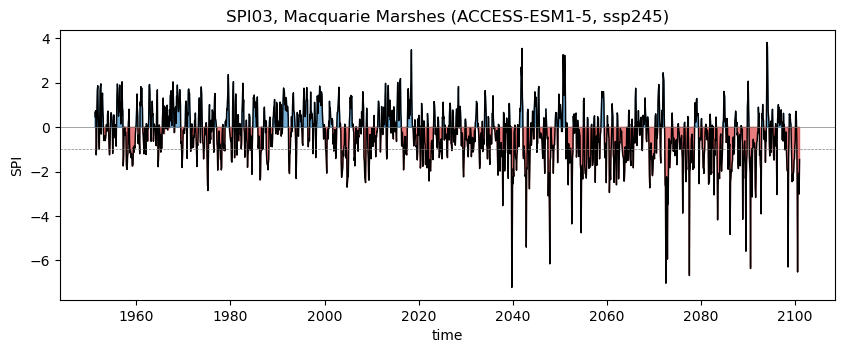

In [55]:
spi = sub["SPI03"]                        
ts = spi.mean(dim=["rlat", "rlon"])        # area mean over the marshes cells

fig, ax = plt.subplots(figsize=(10, 3.5))
ts.plot(ax=ax, color="k", lw=1)
ax.fill_between(ts.time.values, ts.values, 0, where=ts.values >= 0, color="tab:blue", alpha=.6)
ax.fill_between(ts.time.values, ts.values, 0, where=ts.values < 0,  color="tab:red",  alpha=.6)
ax.axhline(0, color="grey", lw=.5)
ax.axhline(-1, ls="--", color="grey", lw=.5)   # moderate drought threshold
ax.set(title="SPI03, Macquarie Marshes (ACCESS-ESM1-5, ssp245)", ylabel="SPI")
fig.savefig(r"C:\Users\szeh4339\OneDrive - The University of Sydney (Staff)\Documents\S1_Narclim\outputs\spi03_access_esm1_5_ssp245.png", dpi=300, bbox_inches="tight")
plt.show()


In [45]:
periods = {
    "1951-2014 (baseline)": ("1951", "2014"),
    "2015-2040": ("2015", "2040"),
    "2041-2070": ("2041", "2070"),
    "2071-2100": ("2071", "2100"),
}

for name, (start, end) in periods.items():
    p = spi.sel(time=slice(start, end))
    print(name, "| months:", p.sizes["time"],
          "| SPI<=-1: %.1f%%" % (100 * float((p <= -1).mean())),
          "| SPI<=-2: %.1f%%" % (100 * float((p <= -2).mean())))

1951-2014 (baseline) | months: 768 | SPI<=-1: 16.5% | SPI<=-2: 2.9%
2015-2040 | months: 312 | SPI<=-1: 31.9% | SPI<=-2: 7.8%
2041-2070 | months: 360 | SPI<=-1: 32.6% | SPI<=-2: 9.8%
2071-2100 | months: 360 | SPI<=-1: 29.1% | SPI<=-2: 10.3%


In [46]:
import pandas as pd

p = spi.sel(time=slice("1980", "2049"))
block5 = (p.time.dt.year // 5) * 5

out = pd.DataFrame({
    "mean SPI": p.mean(dim=["rlat", "rlon"]).groupby(block5).mean().to_series(),
    "% months SPI<=-1": 100 * (p <= -1).mean(dim=["rlat", "rlon"]).groupby(block5).mean().to_series(),
})
print(out.round(2))

      mean SPI  % months SPI<=-1
year                            
1980     -0.14             20.57
1985     -0.19             22.34
1990      0.25             11.20
1995      0.48              3.80
2000     -0.46             31.35
2005     -0.36             28.33
2010      0.15              7.08
2015     -0.28             25.78
2020     -0.03             22.71
2025     -0.27             19.53
2030     -1.46             65.36
2035     -0.32             29.22
2040     -0.32             24.58
2045     -0.07             21.35
